# Lab 8 — K-Means

**Phần bài tập — Nguyễn Đình Huy — 2474802010140**

Mỗi mục/bài là một cell code. Chạy từ trên xuống; hình được lưu vào `figures/`. Dùng `scripts/run_all.py` để lưu thêm nhật ký TXT vào `outputs/`.

## Bài 1 — Tự tính silhouette bằng NumPy

Silhouette tự tính: 0.7227055108; thư viện: 0.7227055108
Khách có s nhỏ nhất: chỉ số 113 (khách thứ 114, dòng CSV 115).
tuoi             38.0
thu_nhap         25.4
diem_chi_tieu    41.0
Cụm 2: a=0.917758, b=0.944750, s=0.028571
Điểm này ít tách biệt hơn các khách còn lại: khoảng cách trong cụm a khá gần khoảng cách sang cụm khác b.
Trên hình thu nhập–chi tiêu, dấu sao đánh dấu khách ở rìa cụm, hướng về nhóm lân cận; s nhỏ không tự động có nghĩa là gán sai.


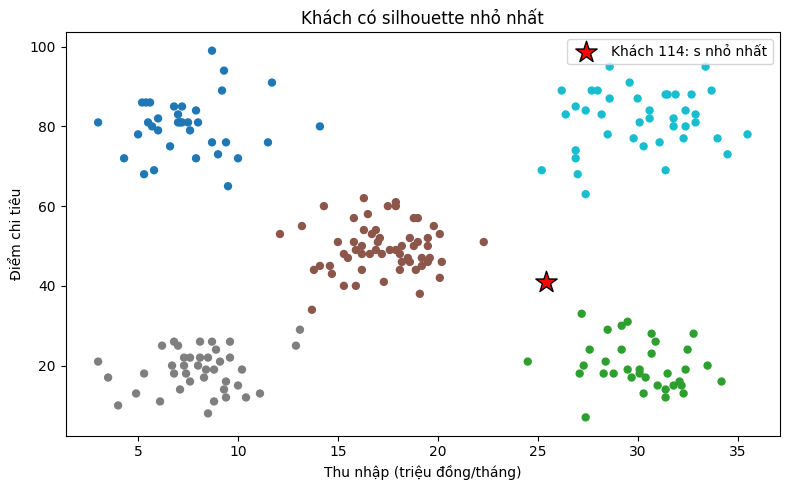

In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

def silhouette_mot_diem(X, nhan, i):
    """Trả (a, b, s); không tính chính điểm i vào khoảng cách trong cụm."""
    X, nhan = np.asarray(X), np.asarray(nhan)
    if not 2 <= len(np.unique(nhan)) <= len(X) - 1:
        raise ValueError("Silhouette cần từ 2 đến n-1 cụm.")
    khoang_cach = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    cung_cum = nhan == nhan[i]
    cung_cum[i] = False
    b = min(khoang_cach[nhan == k].mean() for k in np.unique(nhan) if k != nhan[i])
    if not cung_cum.any():
        return 0.0, b, 0.0  # Cụm đơn điểm: quy ước s = 0 như sklearn.
    a = khoang_cach[cung_cum].mean()
    s = (b - a) / max(a, b) if max(a, b) > 0 else 0.0
    return a, b, s

df = pd.read_csv(tep_du_lieu("khach_hang.csv"))
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
ket_qua = np.array([silhouette_mot_diem(Xs, km.labels_, i) for i in range(len(Xs))])
tu_tinh = ket_qua[:, 2].mean()
thu_vien = silhouette_score(Xs, km.labels_)
print(f"Silhouette tự tính: {tu_tinh:.10f}; thư viện: {thu_vien:.10f}")
assert np.isclose(tu_tinh, thu_vien)
i = int(ket_qua[:, 2].argmin())
print(f"Khách có s nhỏ nhất: chỉ số {i} (khách thứ {i + 1}, dòng CSV {i + 2}).")
print(df.iloc[i].to_string())
print(f"Cụm {km.labels_[i]}: a={ket_qua[i, 0]:.6f}, b={ket_qua[i, 1]:.6f}, s={ket_qua[i, 2]:.6f}")
print("Điểm này ít tách biệt hơn các khách còn lại: khoảng cách trong cụm a khá gần khoảng cách sang cụm khác b.")
print("Trên hình thu nhập–chi tiêu, dấu sao đánh dấu khách ở rìa cụm, hướng về nhóm lân cận; s nhỏ không tự động có nghĩa là gán sai.")
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df.thu_nhap, df.diem_chi_tieu, c=km.labels_, cmap="tab10", s=25)
ax.scatter(df.thu_nhap.iloc[i], df.diem_chi_tieu.iloc[i], marker="*", s=260, c="red", edgecolors="black", label=f"Khách {i + 1}: s nhỏ nhất")
ax.set(xlabel="Thu nhập (triệu đồng/tháng)", ylabel="Điểm chi tiêu", title="Khách có silhouette nhỏ nhất")
ax.legend()
fig.tight_layout()
plt.savefig(thu_muc_hinh / "silhouette_nho_nhat.png", dpi=150)
plt.show()


## Bài 2 — Thêm cột tuổi

K
2     0.3730
3     0.4220
4     0.4558
5     0.4808
6     0.4760
7     0.4627
8     0.4596
9     0.4622
10    0.4573

K tốt nhất = 5; vẫn là 5.
Tâm 3 biến, sắp theo thu nhập:
    tuoi  thu_nhap  diem_chi_tieu  so_khach
0  44.88      8.04          18.85        40
1  25.13      8.48          77.56        39
4  41.65     17.58          49.18        57
2  42.86     30.13          19.97        35
3  32.08     30.28          82.00        39

Mô hình 2 biến, thêm tuổi trung bình để đối chiếu:
      tuoi  thu_nhap  diem_chi_tieu  so_khach
cum                                          
0    24.94      7.48          80.20        35
3    44.88      8.04          18.85        40
2    40.45     17.39          49.30        60
1    42.86     30.13          19.97        35
4    32.62     30.21          81.53        40

Bảng chéo hai cách phân cụm:
Cụm 3 biến   0   1   2   3   4
Cụm 2 biến                    
0            0  35   0   0   0
1            0   0  35   0   0
2            0   4   0   0  56


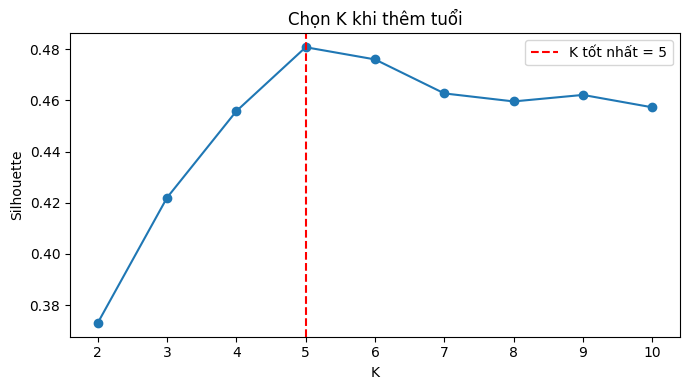

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv(tep_du_lieu("khach_hang.csv"))
cot = ["tuoi", "thu_nhap", "diem_chi_tieu"]
sc = StandardScaler().fit(df[cot])
Xs = sc.transform(df[cot])
models = {k: KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs) for k in range(2, 11)}
scores = {k: silhouette_score(Xs, m.labels_) for k, m in models.items()}
print(pd.Series(scores, name="silhouette").rename_axis("K").round(4).to_string())
k_tot = max(scores, key=scores.get)
km = models[k_tot]
print(f"\nK tốt nhất = {k_tot}; {'vẫn là 5' if k_tot == 5 else 'khác 5'}.")
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=cot)
tam["so_khach"] = np.bincount(km.labels_)
print("Tâm 3 biến, sắp theo thu nhập:")
print(tam.sort_values("thu_nhap").round(2).to_string())
# So với mô hình hai biến của mục 3; so đặc trưng, không so số hiệu cụm.
sc2 = StandardScaler().fit(df[["thu_nhap", "diem_chi_tieu"]])
km2 = KMeans(n_clusters=5, n_init=10, random_state=0).fit(sc2.transform(df[["thu_nhap", "diem_chi_tieu"]]))
cu = df.assign(cum=km2.labels_).groupby("cum")[cot].mean()
cu["so_khach"] = np.bincount(km2.labels_)
print("\nMô hình 2 biến, thêm tuổi trung bình để đối chiếu:")
print(cu.sort_values("thu_nhap").round(2).to_string())
print("\nBảng chéo hai cách phân cụm:")
print(pd.crosstab(pd.Series(km2.labels_, name="Cụm 2 biến"), pd.Series(km.labels_, name="Cụm 3 biến")).to_string())
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(km2.labels_, km.labels_)
print(f"ARI giữa hai cách chia = {ari:.4f}.")
print("Thêm tuổi làm khoảng cách xét cả khác biệt tuổi sau chuẩn hóa. " +
      ("Các nhóm giữ nguyên nên tâm thu nhập và chi tiêu giữ nguyên; tuổi trở thành một tọa độ tâm." if np.isclose(ari, 1)
       else "Thành viên cụm thay đổi, kéo theo tâm thu nhập và chi tiêu thay đổi; đọc các tâm theo đặc trưng thay vì số cụm."))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(scores), list(scores.values()), "o-")
ax.axvline(k_tot, linestyle="--", color="red", label=f"K tốt nhất = {k_tot}")
ax.set(xlabel="K", ylabel="Silhouette", title="Chọn K khi thêm tuổi", xticks=range(2, 11))
ax.legend()
fig.tight_layout()
plt.savefig(thu_muc_hinh / "chon_k_them_tuoi.png", dpi=150)
plt.show()


## Bài 3 — K-Means++ và khởi tạo ngẫu nhiên

random: 30/50 lần đạt inertia làm tròn 23.0; min=23.0167, max=204.0456
k-means++: 50/50 lần đạt inertia làm tròn 23.0; min=23.0167, max=23.0167
Trong 50 seed này, cách đạt nghiệm tốt nhiều nhất là k-means++.
K-Means++ ưu tiên các tâm cách xa nhau, giảm nguy cơ nhiều tâm cùng nằm trong một nhóm. Nó vẫn không bảo đảm cực tiểu toàn cục; n_init > 1 tăng cơ hội chọn nghiệm tốt.


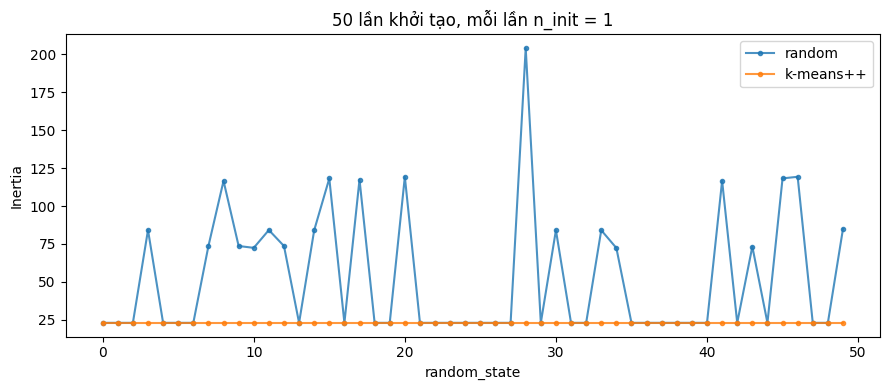

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv(tep_du_lieu("khach_hang.csv"))
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])
ket_qua = {}
for cach in ["random", "k-means++"]:
    inertias = np.array([KMeans(n_clusters=5, init=cach, n_init=1, random_state=rs).fit(Xs).inertia_
                        for rs in range(50)])
    ket_qua[cach] = inertias
    # 23.0 trong đề là số làm tròn một chữ số, không phải đúng 23 tuyệt đối.
    thanh_cong = int(np.sum(np.round(inertias, 1) == 23.0))
    print(f"{cach}: {thanh_cong}/50 lần đạt inertia làm tròn 23.0; min={inertias.min():.4f}, max={inertias.max():.4f}")
so_lan = {c: int(np.sum(np.round(v, 1) == 23.0)) for c, v in ket_qua.items()}
print(f"Trong 50 seed này, cách đạt nghiệm tốt nhiều nhất là {max(so_lan, key=so_lan.get)}.")
print("K-Means++ ưu tiên các tâm cách xa nhau, giảm nguy cơ nhiều tâm cùng nằm trong một nhóm. Nó vẫn không bảo đảm cực tiểu toàn cục; n_init > 1 tăng cơ hội chọn nghiệm tốt.")
fig, ax = plt.subplots(figsize=(9, 4))
for cach, inertias in ket_qua.items():
    ax.plot(range(50), inertias, ".-", alpha=0.8, label=cach)
ax.set(xlabel="random_state", ylabel="Inertia", title="50 lần khởi tạo, mỗi lần n_init = 1")
ax.legend()
fig.tight_layout()
plt.savefig(thu_muc_hinh / "so_sanh_khoi_tao.png", dpi=150)
plt.show()


## Bài 4 — Lưu ảnh nén và dùng ảnh cá nhân

anh_goc.png: 427 x 640; 550,154 byte
anh_16_mau.png: 134,431 byte; tỷ lệ gốc/nén = 4.09
Sai lệch trung bình = 7.97 mức sáng



anh_ca_nhan_goc.png: 974 x 732; 545,830 byte
anh_ca_nhan_16_mau.png: 87,072 byte; tỷ lệ gốc/nén = 6.27
Sai lệch trung bình = 3.37 mức sáng

So sánh cùng định dạng PNG bằng số byte thực tế, không so JPEG đầu vào với PNG đầu ra.
Tỷ lệ 6 lần trong đề là 24/4 bit cho chỉ số màu, chưa tính bảng màu; imsave lưu PNG RGB/RGBA nên dung lượng còn phụ thuộc mã hóa PNG và cấu trúc ảnh.


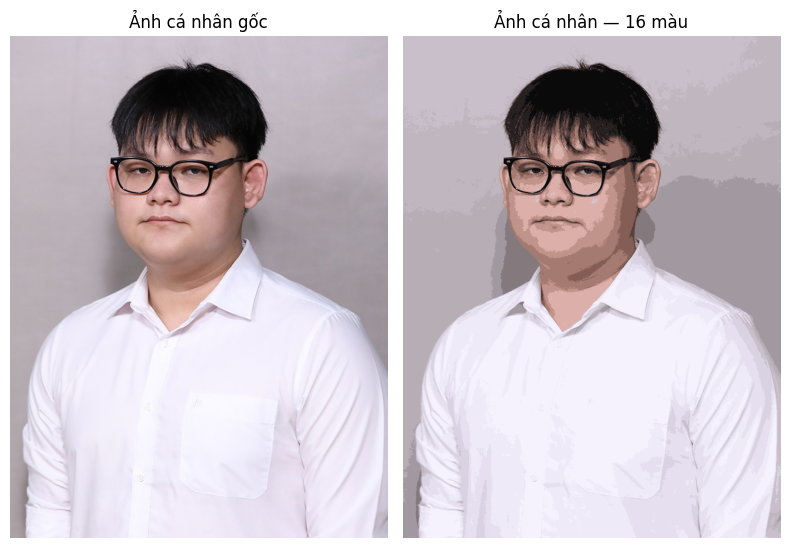

In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.datasets import load_sample_image

def nen_va_luu(anh, ten_goc, ten_nen):
    anh = np.asarray(anh)
    if anh.ndim == 2:
        anh = np.repeat(anh[:, :, None], 3, axis=2)
    anh = anh[:, :, :3]  # Bỏ kênh alpha nếu là RGBA.
    if np.issubdtype(anh.dtype, np.integer):
        anh = anh.astype(float) / np.iinfo(anh.dtype).max
    anh = np.clip(anh, 0, 1)
    cao, rong, _ = anh.shape
    diem = anh.reshape(-1, 3)
    rng = np.random.default_rng(0)
    mau = diem[rng.choice(len(diem), min(5000, len(diem)), replace=False)]
    km = KMeans(n_clusters=16, n_init=4, random_state=0).fit(mau)
    anh_moi = km.cluster_centers_[km.predict(diem)].reshape(cao, rong, 3)
    plt.imsave(thu_muc_hinh / ten_goc, anh)
    plt.imsave(thu_muc_hinh / ten_nen, anh_moi)
    dung_luong_goc = (thu_muc_hinh / ten_goc).stat().st_size
    dung_luong_nen = (thu_muc_hinh / ten_nen).stat().st_size
    print(f"{ten_goc}: {cao} x {rong}; {dung_luong_goc:,} byte")
    print(f"{ten_nen}: {dung_luong_nen:,} byte; tỷ lệ gốc/nén = {dung_luong_goc / dung_luong_nen:.2f}")
    print(f"Sai lệch trung bình = {np.abs(anh_moi - anh).mean() * 255:.2f} mức sáng\n")
    return anh, anh_moi

anh_goc, anh_16 = nen_va_luu(load_sample_image("china.jpg"), "anh_goc.png", "anh_16_mau.png")
anh_ca_nhan = plt.imread(tep_du_lieu("2474802010140.jpg"))
ca_nhan_goc, ca_nhan_nen = nen_va_luu(anh_ca_nhan, "anh_ca_nhan_goc.png", "anh_ca_nhan_16_mau.png")
print("So sánh cùng định dạng PNG bằng số byte thực tế, không so JPEG đầu vào với PNG đầu ra.")
print("Tỷ lệ 6 lần trong đề là 24/4 bit cho chỉ số màu, chưa tính bảng màu; imsave lưu PNG RGB/RGBA nên dung lượng còn phụ thuộc mã hóa PNG và cấu trúc ảnh.")
fig, axes = plt.subplots(1, 2, figsize=(8, 6))
for ax, anh, title in zip(axes, [ca_nhan_goc, ca_nhan_nen], ["Ảnh cá nhân gốc", "Ảnh cá nhân — 16 màu"]):
    ax.imshow(anh)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "so_sanh_anh_ca_nhan.png", dpi=150)
plt.show()


## Bài 5 — DBSCAN trên hai vầng trăng

K-Means: ARI = 0.2475
eps=0.2: 1 cụm, 40 điểm nhiễu; ARI=-0.0014; không tốt hơn K-Means theo ARI.
eps=0.3: 1 cụm, 10 điểm nhiễu; ARI=0.0012; không tốt hơn K-Means theo ARI.
eps=0.4: 1 cụm, 3 điểm nhiễu; ARI=-0.0001; không tốt hơn K-Means theo ARI.
eps là bán kính lân cận: quá nhỏ làm đứt cụm và tăng nhiễu; quá lớn có thể nối hai vành trăng thành một cụm.
ARI so sánh với nhãn thật, không phụ thuộc hoán đổi số cụm; nhãn thật chỉ dùng để đánh giá sau phân cụm.


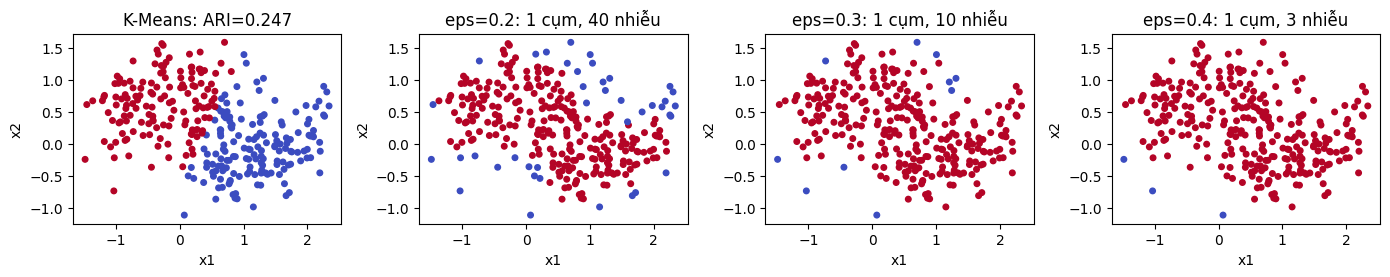

In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)
ari_km = adjusted_rand_score(df.nhan, km.labels_)
print(f"K-Means: ARI = {ari_km:.4f}")
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
labels_list = [km.labels_]
titles = [f"K-Means: ARI={ari_km:.3f}"]
for e in [0.2, 0.3, 0.4]:
    nhan = DBSCAN(eps=e, min_samples=5).fit_predict(X)
    so_cum = len(set(nhan) - {-1})
    so_nhieu = int(np.sum(nhan == -1))
    ari = adjusted_rand_score(df.nhan, nhan)
    print(f"eps={e:.1f}: {so_cum} cụm, {so_nhieu} điểm nhiễu; ARI={ari:.4f}; " +
          ("tốt hơn K-Means theo ARI." if ari > ari_km else "không tốt hơn K-Means theo ARI."))
    labels_list.append(nhan)
    titles.append(f"eps={e}: {so_cum} cụm, {so_nhieu} nhiễu")
print("eps là bán kính lân cận: quá nhỏ làm đứt cụm và tăng nhiễu; quá lớn có thể nối hai vành trăng thành một cụm.")
print("ARI so sánh với nhãn thật, không phụ thuộc hoán đổi số cụm; nhãn thật chỉ dùng để đánh giá sau phân cụm.")
for ax, labels, title in zip(axes, labels_list, titles):
    ax.scatter(df.x1, df.x2, c=labels, cmap="coolwarm", s=16)
    ax.set(xlabel="x1", ylabel="x2", title=title)
    ax.set_aspect("equal")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "dbscan_hai_vang_trang.png", dpi=150)
plt.show()


## Bài 6 — Phân cụm chữ số viết tay

Cụm            0    1    2   3    4    5    6    7    8    9
Chữ số thật                                                 
0            176    0    0   0    0    0    2    0    0    0
1              0  100    0  54    1    2    0    1    0   24
2              1    8    3   2   13    0    0    0    2  148
3              0    7    7   0  154    0    0    2   13    0
4              0    2   11   3    0    0  165    0    0    0
5              0    0    0   0    2    1    2  136   41    0
6              1    3    0   0    0  177    0    0    0    0
7              0    2  174   2    0    0    0    1    0    0
8              0  100    5   6    2    2    0    4   52    3
9              0    1    8  20    6    0    0    6  139    0

Tỷ lệ mỗi chữ số nằm trong cụm đông nhất của nó:
Chữ số thật
0    0.9888
1    0.5495
2    0.8362
3    0.8415
4    0.9116
5    0.7473
6    0.9779
7    0.9721
8    0.5747
9    0.7722
Chữ số 0 được gom gọn nhất: 98.88% nằm trong cụm 0.
Cụm 1 trộn nhiều chữ số: 1 (100 ản

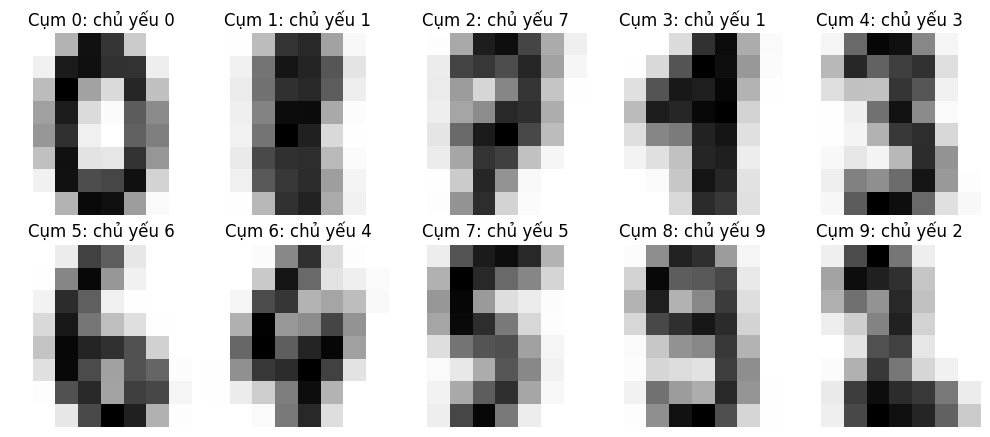

In [6]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.datasets import load_digits
digits = load_digits()
# Chỉ đưa ảnh vào fit; nhãn thật chưa được dùng để huấn luyện.
km = KMeans(n_clusters=10, n_init=10, random_state=0).fit(digits.data)
bang = pd.crosstab(pd.Series(digits.target, name="Chữ số thật"), pd.Series(km.labels_, name="Cụm"))
print(bang.to_string())
ty_le = bang.max(axis=1) / bang.sum(axis=1)
print("\nTỷ lệ mỗi chữ số nằm trong cụm đông nhất của nó:")
print(ty_le.round(4).to_string())
gom_gon = ty_le.idxmax()
print(f"Chữ số {gom_gon} được gom gọn nhất: {ty_le[gom_gon]:.2%} nằm trong cụm {bang.loc[gom_gon].idxmax()}.")
for cum in bang.columns:
    dong = bang[cum].sort_values(ascending=False)
    # In các cụm có ít nhất hai chữ số chiếm >= 10% cụm.
    if dong.iloc[1] / dong.sum() >= 0.1:
        print(f"Cụm {cum} trộn nhiều chữ số: {dong.index[0]} ({dong.iloc[0]} ảnh), {dong.index[1]} ({dong.iloc[1]} ảnh), tổng {dong.sum()}.")
print("K-Means nhóm theo khoảng cách pixel, nên các nét tương tự có thể bị gom chung; một chữ số có nhiều kiểu viết cũng có thể bị tách thành nhiều cụm.")
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for k, ax in enumerate(axes.flat):
    ax.imshow(km.cluster_centers_[k].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Cụm {k}: chủ yếu {bang[k].idxmax()}")
    ax.axis("off")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "tam_cum_chu_so.png", dpi=150)
plt.show()
